In [1]:
import warnings
warnings.filterwarnings('ignore')

In [6]:
import pandas as pd
import numpy as np
import re
import string 
from wordcloud import WordCloud
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

import os
import joblib

In [3]:
df = pd.read_csv("mail_data.csv")

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5572, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# Encoding

In [4]:
# Encode target variable
encoder = LabelEncoder()
df['Category'] = encoder.fit_transform(df['Category'])  # spam=1, ham=0

df[['Message', 'Category']].head()

,Message,Category
0,"Go until jurong point, crazy.. Available only ...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives aro...",0


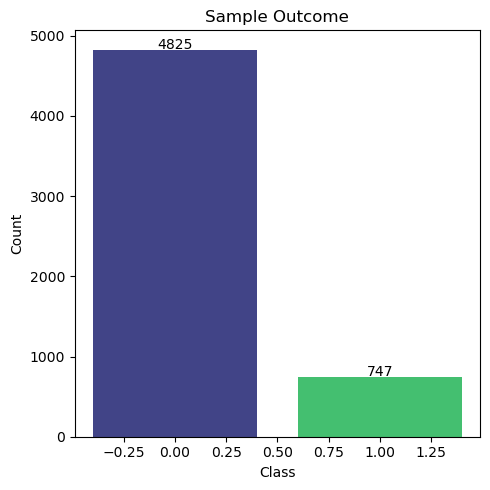

In [8]:
target = df['Category'].value_counts()
labels = sorted(target.index.tolist())
sizes = target.reindex(labels).values

# Bar chart
plt.figure(figsize=(5, 5))
plt.bar(labels, sizes, color=plt.cm.viridis([0.2, 0.7]))
plt.title("Sample Outcome")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.ylabel("Count")

# Show counts above bars
for i, v in enumerate(sizes):
    plt.text(i, v + 5, str(v), ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# Data Cleaning

In [10]:
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    
    # Remove URLs
    text = re.sub(r'http\S+|www.\S+', ' ', text)
    
    # Remove digits and special characters
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    
    # Lowercase
    text = text.lower()
    
    # Strip extra spaces
    text = text.strip()
    
    return text

df['clean_text'] = df['Message'].apply(clean_text)
df[['Message', 'clean_text']].head()


,Message,clean_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives aro...


# Tokenization

In [11]:
nltk.download('punkt')

df['tokens'] = df['clean_text'].apply(lambda x: word_tokenize(x))
df[['clean_text', 'tokens']].head()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\TruProjects\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


,clean_text,tokens
0,go until jurong point crazy available only ...,"[go, until, jurong, point, crazy, available, o..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in a wkly comp to win fa cup fina...,"[free, entry, in, a, wkly, comp, to, win, fa, ..."
3,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t..."
4,nah i don t think he goes to usf he lives aro...,"[nah, i, don, t, think, he, goes, to, usf, he,..."


# Stopword Removal

In [12]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

df['tokens'] = df['tokens'].apply(remove_stopwords)
df[['clean_text', 'tokens']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\TruProjects\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,clean_text,tokens
0,go until jurong point crazy available only ...,"[go, jurong, point, crazy, available, bugis, n..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in a wkly comp to win fa cup fina...,"[free, entry, wkly, comp, win, fa, cup, final,..."
3,u dun say so early hor u c already then say,"[u, dun, say, early, hor, u, c, already, say]"
4,nah i don t think he goes to usf he lives aro...,"[nah, think, goes, usf, lives, around, though]"


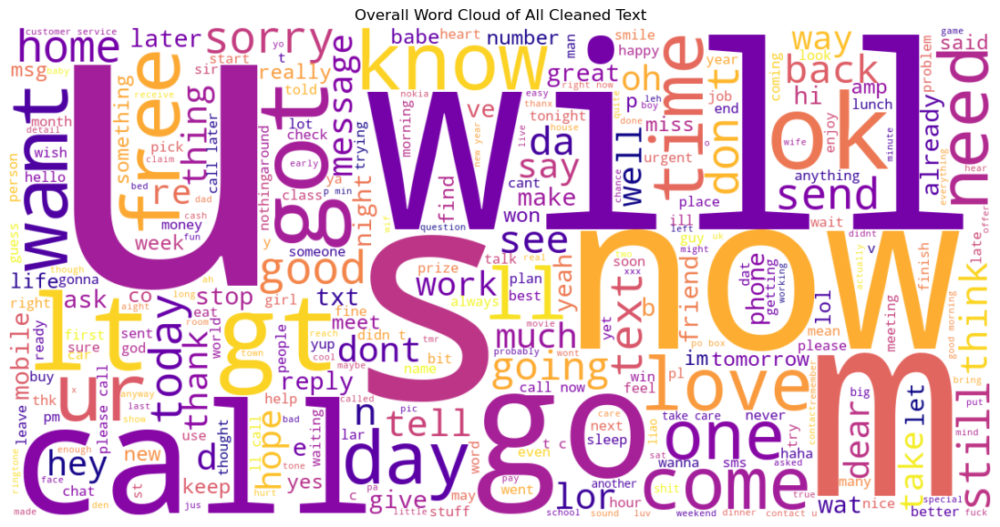

In [14]:
all_text = " ".join(df["clean_text"])
wc = WordCloud(width=1200, height=600, background_color="white", colormap="plasma", max_words=300).generate(all_text)

plt.figure(figsize=(14,7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Overall Word Cloud of All Cleaned Text")
plt.show()

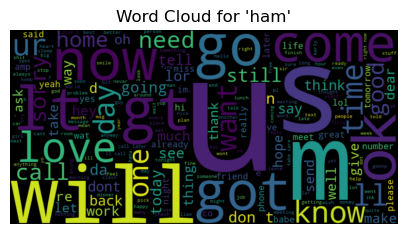

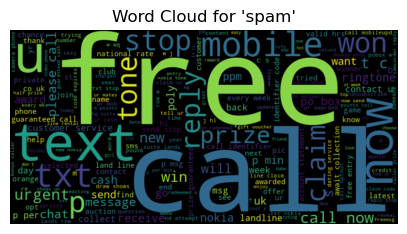

In [18]:
labels = df['Category'].unique()

for label in labels:
    # Convert numeric back to original category name
    label_name = encoder.inverse_transform([label])[0]  

    text_data = df[df['Category'] == label]['clean_text']
    combined_text = " ".join(text_data)

    wc = WordCloud(
        width=800,
        height=400,
        background_color='black',
        colormap='viridis',
        max_words=200
    ).generate(combined_text)

    plt.figure(figsize=(5,3))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Word Cloud for '{label_name}'")  # <-- original name
    plt.show()


# Stemming / Lemmatization

In [9]:
nltk.download('wordnet')
ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def stem_and_lemmatize(tokens):
    # Apply stemming and lemmatization
    return [lemmatizer.lemmatize(ps.stem(word)) for word in tokens]

df['processed_tokens'] = df['tokens'].apply(stem_and_lemmatize)
df[['tokens', 'processed_tokens']].head()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\TruProjects\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


,tokens,processed_tokens
0,"[go, jurong, point, crazy, available, bugis, n...","[go, jurong, point, crazi, avail, bugi, n, gre..."
1,"[ok, lar, joking, wif, u, oni]","[ok, lar, joke, wif, u, oni]"
2,"[free, entry, wkly, comp, win, fa, cup, final,...","[free, entri, wkli, comp, win, fa, cup, final,..."
3,"[u, dun, say, early, hor, u, c, already, say]","[u, dun, say, earli, hor, u, c, alreadi, say]"
4,"[nah, think, goes, usf, lives, around, though]","[nah, think, goe, usf, live, around, though]"


In [10]:
df['final_text'] = df['processed_tokens'].apply(lambda x: ' '.join(x))
df[['final_text', 'Category']].head()


,final_text,Category
0,go jurong point crazi avail bugi n great world...,0
1,ok lar joke wif u oni,0
2,free entri wkli comp win fa cup final tkt st m...,1
3,u dun say earli hor u c alreadi say,0
4,nah think goe usf live around though,0


# TF-IDF Vectorization

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=5000)  # limit features to speed up
X = tfidf.fit_transform(df['final_text']).toarray()
y = df['Category']

In [32]:
joblib.dump(tfidf, "Models/tfidf_vectorizer.pkl")

['Models/tfidf_vectorizer.pkl']

In [11]:
df['Category'].value_counts()

0    4825
1     747
Name: Category, dtype: int64

# Oversampling with SMOTE

In [13]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# Train-Test Split

In [14]:

X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42, stratify=y_res)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 7720
Testing samples: 1930


In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

ML_Model = []
accuracy = []
precision = []
recall = []
f1score = []

#function to call for storing the results
def storeResults(model, a,b,c,d):
    ML_Model.append(model)
    accuracy.append(round(a, 3))
    precision.append(round(d, 3))
    recall.append(round(c, 3))
    f1score.append(round(b, 3))

In [43]:
labels = ['Not Spam', 'Spam']

# DecisionTree

Decision Tree Accuracy: 0.9207253886010363
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       965
           1       0.91      0.93      0.92       965

    accuracy                           0.92      1930
   macro avg       0.92      0.92      0.92      1930
weighted avg       0.92      0.92      0.92      1930



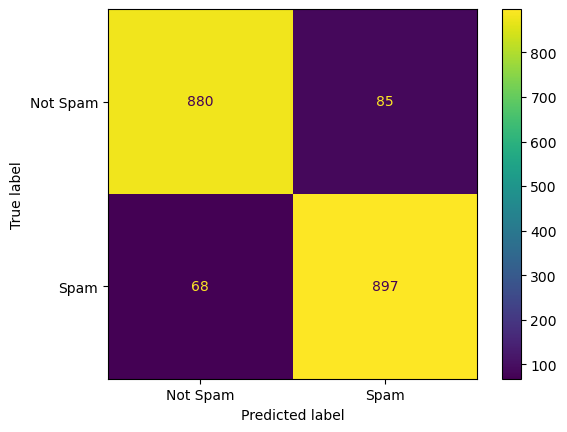

In [17]:
from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree
dt = DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)  
dt.fit(X_train, y_train)

# Predict on test set
y_pred_dt = dt.predict(X_test)

# Evaluation metrics
dt_acc = accuracy_score(y_test, y_pred_dt)
dt_prec = precision_score(y_test, y_pred_dt, average="weighted")
dt_rec = recall_score(y_test, y_pred_dt, average="weighted")
dt_f1 = f1_score(y_test, y_pred_dt, average="weighted")

# Confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=labels)
disp_dt.plot(cmap="viridis")

# Print results
print("Decision Tree Accuracy:", dt_acc)
print(classification_report(y_test, y_pred_dt))


In [44]:
storeResults("DecisionTree", dt_acc, dt_prec, dt_rec, dt_f1)

# RandomForest

Random Forest Accuracy: 0.9264248704663213
              precision    recall  f1-score   support

           0       0.87      1.00      0.93       965
           1       1.00      0.86      0.92       965

    accuracy                           0.93      1930
   macro avg       0.93      0.93      0.93      1930
weighted avg       0.93      0.93      0.93      1930



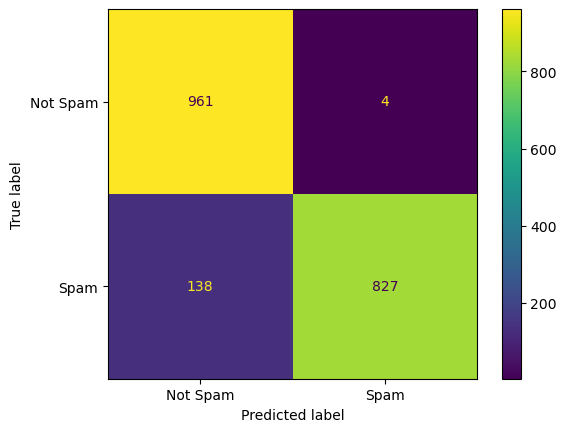

In [18]:
from sklearn.ensemble import RandomForestClassifier


rf = RandomForestClassifier(n_estimators=50, max_depth=5, min_samples_leaf=5, random_state=42, n_jobs=-1)  
rf.fit(X_train, y_train)


y_pred_rf = rf.predict(X_test)

# Evaluation metrics
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, average="weighted")
rf_rec = recall_score(y_test, y_pred_rf, average="weighted")
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=labels)
disp_rf.plot(cmap="viridis")

# Print results
print("Random Forest Accuracy:", rf_acc)
print(classification_report(y_test, y_pred_rf))


In [45]:
storeResults('RandomForest', rf_acc, rf_prec, rf_rec, rf_f1)

# Naive Bayes

Logistic Regression Accuracy: 0.9720207253886011
              precision    recall  f1-score   support

           0       0.99      0.96      0.97       965
           1       0.96      0.99      0.97       965

    accuracy                           0.97      1930
   macro avg       0.97      0.97      0.97      1930
weighted avg       0.97      0.97      0.97      1930



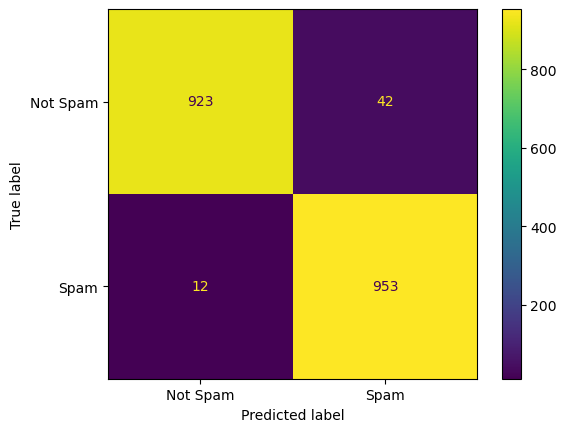

In [25]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB(alpha=2.0)
nb.fit(X_train, y_train)

y_pred = nb.predict(X_test)

nb_acc = accuracy_score(y_test, y_pred)
nb_prec = precision_score(y_test, y_pred, average="weighted")
nb_rec = recall_score(y_test, y_pred, average="weighted")
nb_f1 = f1_score(y_test, y_pred, average="weighted")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="viridis")

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

In [46]:
storeResults('NaiveBayes', nb_acc, nb_prec, nb_rec, nb_f1)

# ExtraTrees

Extra Trees Classifier Accuracy: 0.9316062176165804
              precision    recall  f1-score   support

           0       0.88      1.00      0.94       965
           1       1.00      0.86      0.93       965

    accuracy                           0.93      1930
   macro avg       0.94      0.93      0.93      1930
weighted avg       0.94      0.93      0.93      1930



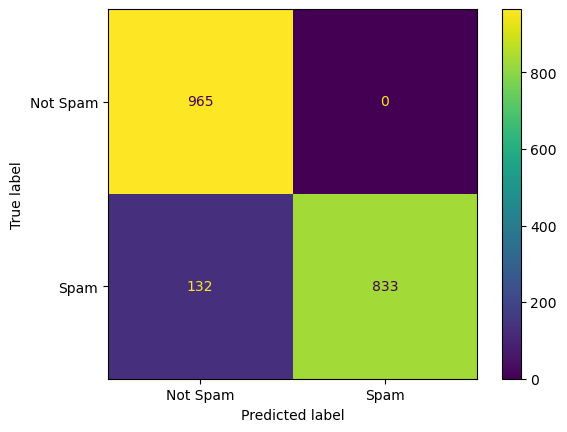

In [23]:
from sklearn.ensemble import ExtraTreesClassifier

# Initialize Extra Trees Classifier
etc = ExtraTreesClassifier(n_estimators=100, max_depth=10,  random_state=42, n_jobs=-1) 
etc.fit(X_train, y_train)

# Predict on test set
y_pred_etc = etc.predict(X_test)

# Evaluation metrics
etc_acc = accuracy_score(y_test, y_pred_etc)
etc_prec = precision_score(y_test, y_pred_etc, average="weighted")
etc_rec = recall_score(y_test, y_pred_etc, average="weighted")
etc_f1 = f1_score(y_test, y_pred_etc, average="weighted")

# Confusion matrix
cm_etc = confusion_matrix(y_test, y_pred_etc)
disp_etc = ConfusionMatrixDisplay(confusion_matrix=cm_etc, display_labels=labels)
disp_etc.plot(cmap="viridis")

# Print results
print("Extra Trees Classifier Accuracy:", etc_acc)
print(classification_report(y_test, y_pred_etc))


In [47]:
storeResults('ExtraTrees', etc_acc, etc_prec, etc_rec, etc_f1)

# MLP

MLP Classifier Accuracy: 0.977720207253886
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       965
           1       0.97      0.99      0.98       965

    accuracy                           0.98      1930
   macro avg       0.98      0.98      0.98      1930
weighted avg       0.98      0.98      0.98      1930



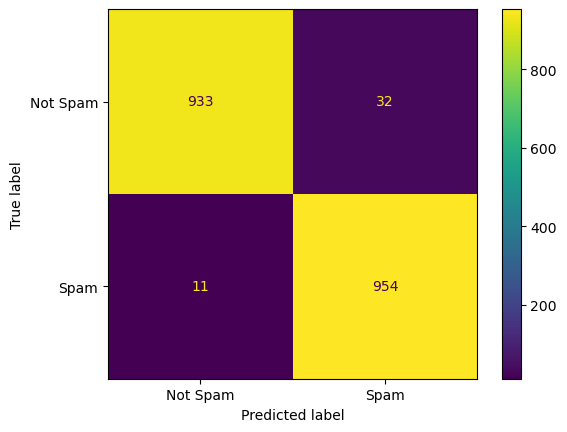

In [34]:
from sklearn.neural_network import MLPClassifier

# Initialize MLP Classifier
mlp = MLPClassifier(max_iter=1, random_state=42)
mlp.fit(X_train, y_train)

# Predict on test set
y_pred_mlp = mlp.predict(X_test)

# Evaluation metrics
mlp_acc = accuracy_score(y_test, y_pred_mlp)
mlp_prec = precision_score(y_test, y_pred_mlp, average="weighted")
mlp_rec = recall_score(y_test, y_pred_mlp, average="weighted")
mlp_f1 = f1_score(y_test, y_pred_mlp, average="weighted")

# Confusion matrix
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
disp_mlp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=labels)
disp_mlp.plot(cmap="viridis")

# Print results
print("MLP Classifier Accuracy:", mlp_acc)
print(classification_report(y_test, y_pred_mlp))


In [48]:
storeResults('MLP', mlp_acc, mlp_prec, mlp_rec, mlp_f1)

# SVM

SVC Accuracy: 0.977720207253886
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       965
           1       0.99      0.97      0.98       965

    accuracy                           0.98      1930
   macro avg       0.98      0.98      0.98      1930
weighted avg       0.98      0.98      0.98      1930



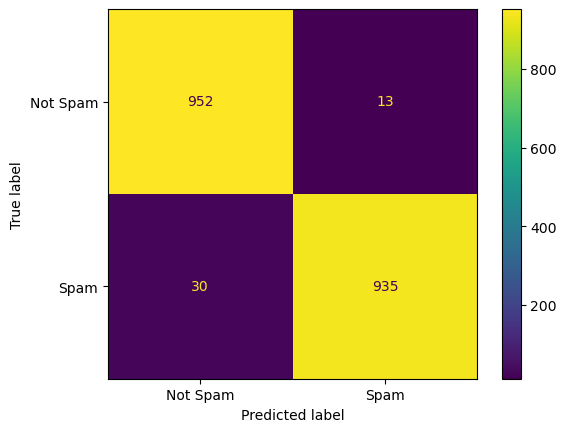

In [36]:
from sklearn.svm import SVC

# Initialize SVC
svc = SVC(kernel='linear', C=0.1, random_state=42)
svc.fit(X_train, y_train)

# Predict on test set
y_pred_svc = svc.predict(X_test)

# Evaluation metrics
svc_acc = accuracy_score(y_test, y_pred_svc)
svc_prec = precision_score(y_test, y_pred_svc, average="weighted")
svc_rec = recall_score(y_test, y_pred_svc, average="weighted")
svc_f1 = f1_score(y_test, y_pred_svc, average="weighted")

# Confusion matrix
cm_svc = confusion_matrix(y_test, y_pred_svc)
disp_svc = ConfusionMatrixDisplay(confusion_matrix=cm_svc, display_labels=labels)
disp_svc.plot(cmap="viridis")

# Print results
print("SVC Accuracy:", svc_acc)
print(classification_report(y_test, y_pred_svc))


In [49]:
storeResults('SVM', svc_acc, svc_prec, svc_rec, svc_f1)

# Voting

Trained and saved VotingClassifier at Models/proposed_voting.pkl
Voting Classifier Accuracy: 0.9533678756476683
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       965
           1       1.00      0.91      0.95       965

    accuracy                           0.95      1930
   macro avg       0.96      0.95      0.95      1930
weighted avg       0.96      0.95      0.95      1930



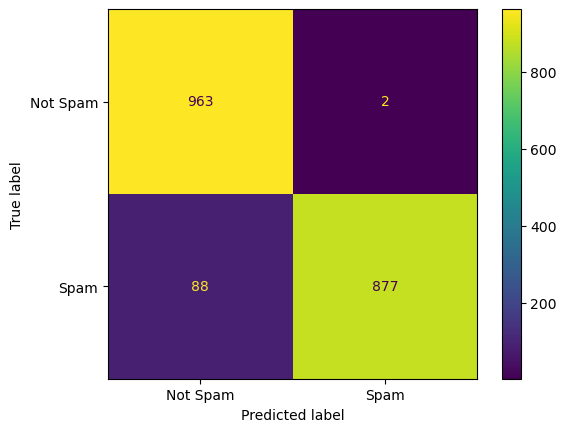

In [37]:
from sklearn.ensemble import VotingClassifier

model_path = "Models/proposed_voting.pkl"
os.makedirs("Models", exist_ok=True)


# # Load or Train VotingClassifier

if os.path.exists(model_path):
    # Load saved model
    vot = joblib.load(model_path)
    print("Loaded VotingClassifier from disk")
else:
    
    # Define base models
    dt  = DecisionTreeClassifier(max_depth=3, min_samples_split=10, random_state=42)
    nb  = MultinomialNB(alpha=2.0)
    rf  = RandomForestClassifier(n_estimators=10, max_depth=4, min_samples_leaf=5, random_state=42, n_jobs=-1)
    etc = ExtraTreesClassifier(n_estimators=10, max_depth=4, min_samples_leaf=5, random_state=42, n_jobs=-1)
    mlp = MLPClassifier(max_iter=1, random_state=42)
    svc = SVC(kernel='linear', C=0.1, gamma=0.01, probability=False, random_state=42)  

    # Create VotingClassifier
    vot = VotingClassifier(
        estimators=[
            ('DT', dt),
            ('NB', nb),
            ('RF', rf),
            ('ETC', etc),
            ('MLP', mlp),
            ('SVC', svc)
        ],
        voting='hard'
    )

    # Train
    vot.fit(X_train, y_train)

    # Save the trained model
    joblib.dump(vot, model_path)
    print(f"Trained and saved VotingClassifier at {model_path}")

# Predict on test data
y_pred_vote = vot.predict(X_test)

# Evaluation metrics
vote_acc = accuracy_score(y_test, y_pred_vote)
vote_prec = precision_score(y_test, y_pred_vote, average="weighted")
vote_rec = recall_score(y_test, y_pred_vote, average="weighted")
vote_f1 = f1_score(y_test, y_pred_vote, average="weighted")

# Confusion matrix
cm_vote = confusion_matrix(y_test, y_pred_vote)
disp_vote = ConfusionMatrixDisplay(confusion_matrix=cm_vote, display_labels=labels)
disp_vote.plot(cmap="viridis")

# Print results
print("Voting Classifier Accuracy:", vote_acc)
print(classification_report(y_test, y_pred_vote))


In [50]:
storeResults("Proposed_Voting", vote_acc, vote_prec, vote_rec, vote_f1)

# Stacking

Trained and saved StackingClassifier at Models/proposed_stacking.pkl
Stacking Classifier Accuracy: 0.9855
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       965
           1       0.98      0.99      0.99       965

    accuracy                           0.99      1930
   macro avg       0.99      0.99      0.99      1930
weighted avg       0.99      0.99      0.99      1930



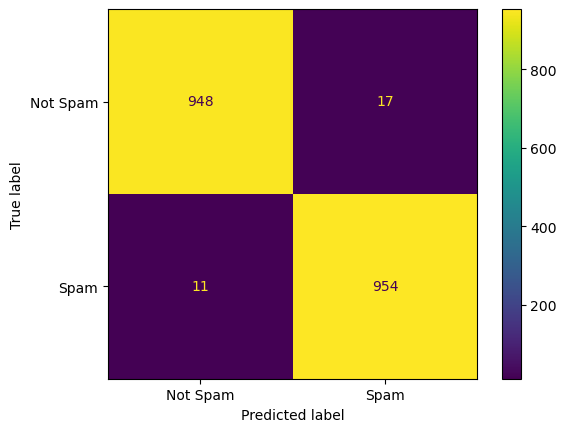

In [38]:
from sklearn.ensemble import StackingClassifier

# Path to save/load the model
model_path = "Models/proposed_stacking.pkl"
os.makedirs("Models", exist_ok=True)


# Load or Train StackingClassifier

if os.path.exists(model_path):
    # Load saved model
    stack = joblib.load(model_path)
    print("Loaded StackingClassifier from disk")
else:
    # Define base models
    dt  = DecisionTreeClassifier(max_depth=3, min_samples_split=10, random_state=42)
    nb  = MultinomialNB(alpha=2.0)
    rf  = RandomForestClassifier(n_estimators=10, max_depth=4, min_samples_leaf=5, random_state=42, n_jobs=-1)
    etc = ExtraTreesClassifier(n_estimators=10, max_depth=4, min_samples_leaf=5, random_state=42, n_jobs=-1)
    mlp = MLPClassifier(max_iter=1, random_state=42)
    svc = SVC(kernel='linear', C=0.1, gamma=0.01, probability=False, random_state=42)

    # Define StackingClassifier
    stack = StackingClassifier(
        estimators=[
            ('DT', dt),
            ('NB', nb),
            ('RF', rf),
            ('ETC', etc),
            ('MLP', mlp),
            ('SVC', svc)
        ],
        final_estimator=MLPClassifier(hidden_layer_sizes=(30,), max_iter=300, random_state=42),
        cv=5,
        passthrough=False, 
        n_jobs=-1
    )

    # Train
    stack.fit(X_train, y_train)

    # Save the trained model
    joblib.dump(stack, model_path)
    print(f"Trained and saved StackingClassifier at {model_path}")


# Predict and Evaluate

y_pred = stack.predict(X_test)

stack_acc = accuracy_score(y_test, y_pred)
stack_prec = precision_score(y_test, y_pred, average="weighted")
stack_rec = recall_score(y_test, y_pred, average="weighted")
stack_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Stacking Classifier Accuracy: {stack_acc:.4f}")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="viridis")


In [51]:
storeResults("Proposed_Stacking", stack_acc, stack_prec, stack_rec, stack_f1)

# Extension

# VotingClassifier

Voting Boosting Classifier Accuracy: 0.9881
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       965
           1       0.99      0.99      0.99       965

    accuracy                           0.99      1930
   macro avg       0.99      0.99      0.99      1930
weighted avg       0.99      0.99      0.99      1930



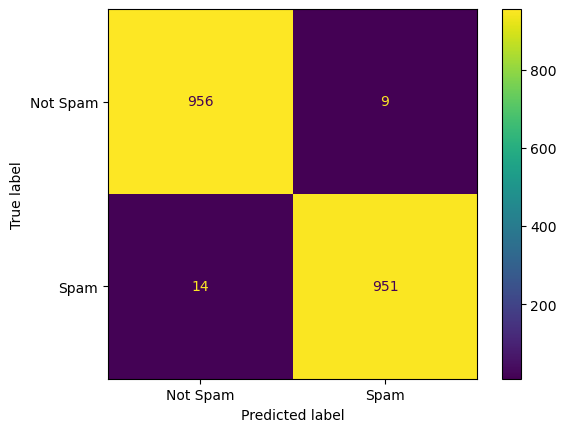

In [41]:
from sklearn.ensemble import VotingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
# Path to save/load the model
model_path = "Models/Extension_voting.pkl"
os.makedirs("Models", exist_ok=True)

# Load or Train VotingClassifier

if os.path.exists(model_path):
    voting = joblib.load(model_path)
    print("Loaded Voting Boosting model from disk")
else:
# Define boosting models
    adb = AdaBoostClassifier(n_estimators=100, random_state=42)
    xgb = XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='mlogloss', random_state=42)
    cat = CatBoostClassifier(iterations=100, verbose=0, random_state=42)

    # Create VotingClassifier with soft voting
    voting = VotingClassifier(
        estimators=[('AdaBoost', adb), ('XGBoost', xgb), ('CatBoost', cat)],
        voting='soft',
        weights=[1, 2, 2],
        n_jobs=-1
    )

    # Train
    voting.fit(X_train, y_train)

    # Save the trained model
    joblib.dump(voting, model_path)
    print(f"Trained and saved Voting Boosting model at {model_path}")


# Predict and Evaluate

y_pred = voting.predict(X_test)

voting_acc = accuracy_score(y_test, y_pred)
voting_prec = precision_score(y_test, y_pred, average="weighted")
voting_rec = recall_score(y_test, y_pred, average="weighted")
voting_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Voting Boosting Classifier Accuracy: {voting_acc:.4f}")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="viridis")


In [52]:
storeResults("Extension_voting", voting_acc, voting_prec, voting_rec, voting_f1)

# StackingClassifier

Loaded Stacking Boosting model from disk
Stacking Boosting Classifier Accuracy: 0.9865
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       965
           1       0.99      0.99      0.99       965

    accuracy                           0.99      1930
   macro avg       0.99      0.99      0.99      1930
weighted avg       0.99      0.99      0.99      1930



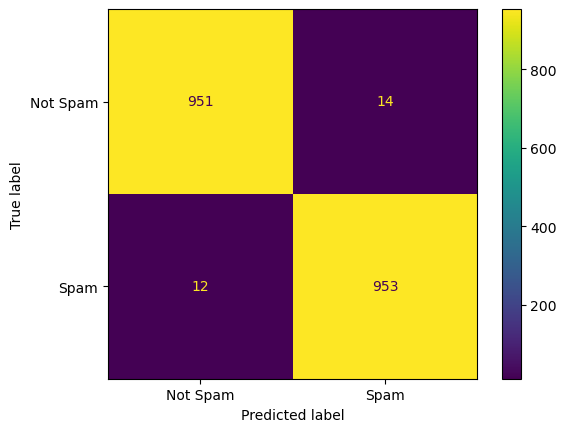

In [56]:
from lightgbm import LGBMClassifier

model_path = "Models/Extension_Stacking.pkl"
os.makedirs("Models", exist_ok=True)


#  Load or Train StackingClassifier

if os.path.exists(model_path):
    stacking = joblib.load(model_path)
    print("Loaded Stacking Boosting model from disk")
else:
    # Define base learners
    adb = AdaBoostClassifier(n_estimators=100, random_state=42)
    xgb = XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='mlogloss', random_state=42)
    cat = CatBoostClassifier(iterations=100, verbose=0, random_state=42)
    lgbm = LGBMClassifier(n_estimators=100, random_state=42)

    stacking = StackingClassifier(
        estimators=[('AdaBoost', adb), ('XGBoost', xgb), ('CatBoost', cat)],
        final_estimator=lgbm,
        cv=5,
        passthrough=False,  
        n_jobs=-1
    )

    # Train
    stacking.fit(X_train, y_train)

    # Save the trained model
    joblib.dump(stacking, model_path)
    print(f"Trained and saved Stacking Boosting model at {model_path}")


# Predict and Evaluate

y_pred = stacking.predict(X_test)

stacking_acc = accuracy_score(y_test, y_pred)
stacking_prec = precision_score(y_test, y_pred, average="weighted")
stacking_rec = recall_score(y_test, y_pred, average="weighted")
stacking_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Stacking Boosting Classifier Accuracy: {stacking_acc:.4f}")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="viridis")

In [57]:
storeResults("Extension_Stacking", stacking_acc, stacking_prec, stacking_rec, stacking_f1)

# Comparison Table

In [58]:

result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'Accuracy' : accuracy,
                       'Precision': precision,
                       'Recall'   : recall,
                        'F1-Score' : f1score,
                      })

In [59]:
result

,ML Model,Accuracy,Precision,Recall,F1-Score
0,DecisionTree,0.921,0.921,0.921,0.921
1,RandomForest,0.926,0.926,0.926,0.935
2,NaiveBayes,0.972,0.972,0.972,0.972
3,ExtraTrees,0.932,0.931,0.932,0.940
4,MLP,0.978,0.978,0.978,0.978
5,SVM,0.978,0.978,0.978,0.978
6,Proposed_Voting,0.953,0.953,0.953,0.957
7,Proposed_Stacking,0.985,0.985,0.985,0.986
8,Extension_voting,0.988,0.988,0.988,0.988
9,Extension_Stacking,0.987,0.987,0.987,0.987


# Comparison Graphs

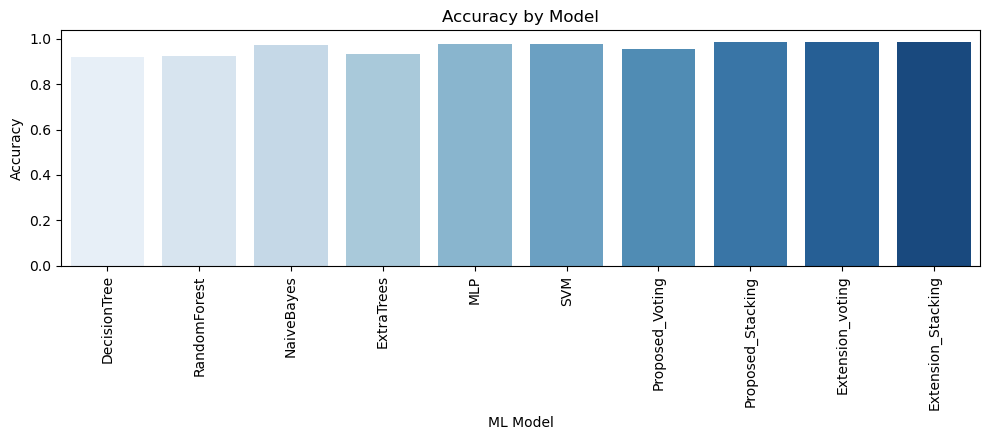

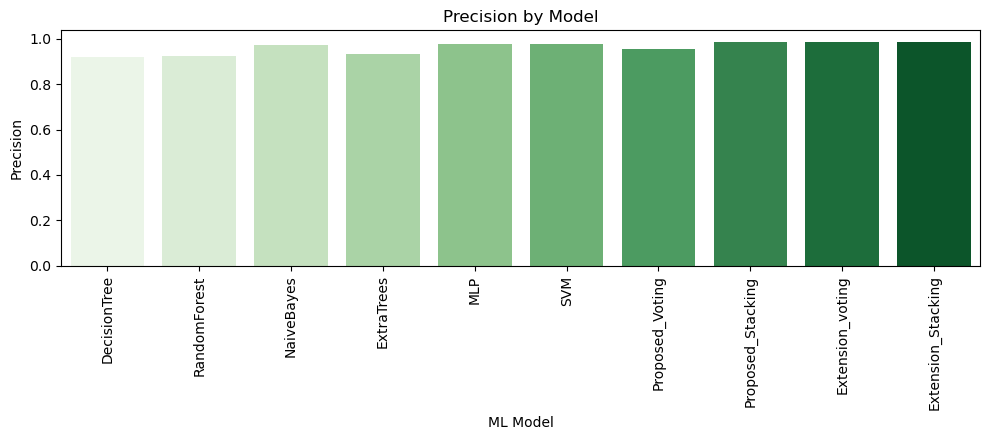

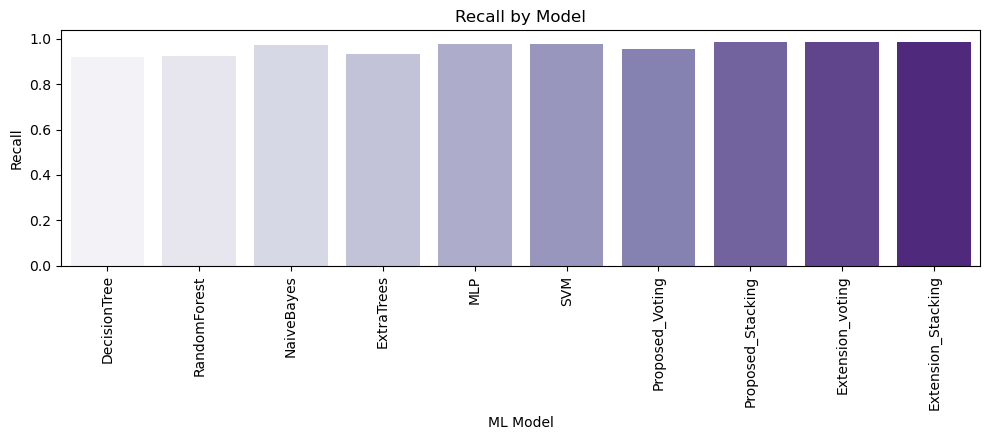

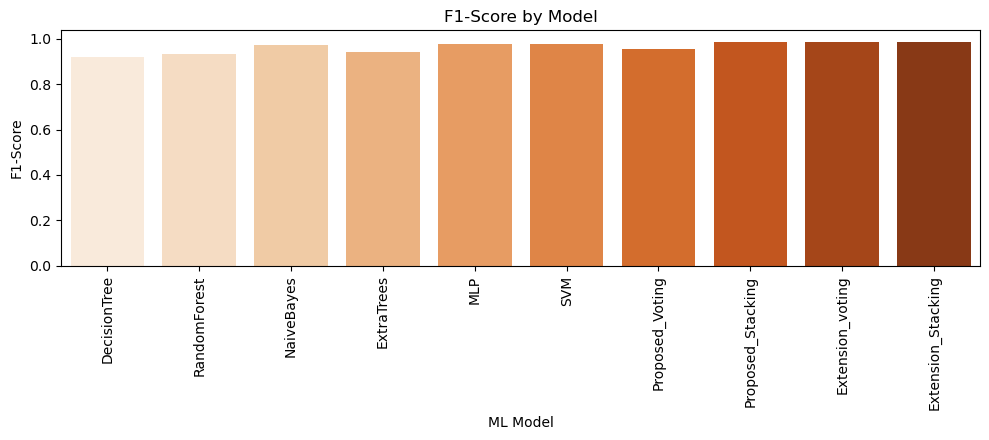

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt


palettes = {
    'Accuracy': 'Blues',
    'Precision': 'Greens',
    'Recall': 'Purples',
    'F1-Score': 'Oranges'
}

for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    plt.figure(figsize=(10, 4.5))
    sns.barplot(data=result, x='ML Model', y=metric, palette=palettes[metric])
    plt.title(f'{metric} by Model')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

# XAI

In [20]:
import joblib

model = joblib.load("Models/Extension_voting.pkl")

# XAI - LIME

In [55]:
from lime.lime_text import LimeTextExplainer
import random
import matplotlib.pyplot as plt

sample_emails = random.sample(list(df['Message']), 10)

explainer = LimeTextExplainer(class_names=['Not Spam', 'spam'])

predict_fn = lambda x: model.predict_proba(tfidf.transform(x))


for i, email_text in enumerate(sample_emails, 1):
    print(f"\n Email {i}: {email_text[:200]}...")  
    exp = explainer.explain_instance(email_text, predict_fn, num_features=10)

   
    exp.show_in_notebook(text=True)




 Email 1: Aiyah then i wait lor. Then u entertain me. Hee......



 Email 2: I love you. You set my soul on fire. It is not just a spark. But it is a flame. A big rawring flame. XoXo...



 Email 3: You have come into my life and brought the sun ..Shiny down on me, warming my heart. Putting a constant smile on my face ... Making me feel loved and cared for...



 Email 4: My birthday is on feb  &lt;#&gt;  da. ....



 Email 5: Yes its possible but dint try. Pls dont tell to any one k...



 Email 6: Yo, you around? Just got my car back...



 Email 7: Thursday night? Yeah, sure thing, we'll work it out then...



 Email 8: Just sent it. So what type of food do you like?...



 Email 9: Although i told u dat i'm into baig face watches now but i really like e watch u gave cos it's fr u. Thanx 4 everything dat u've done today, i'm touched......



 Email 10: either way works for me. I am  &lt;#&gt;  years old. Hope that doesnt bother you....


# XAI - SHAP

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP shape: (100, 5000)


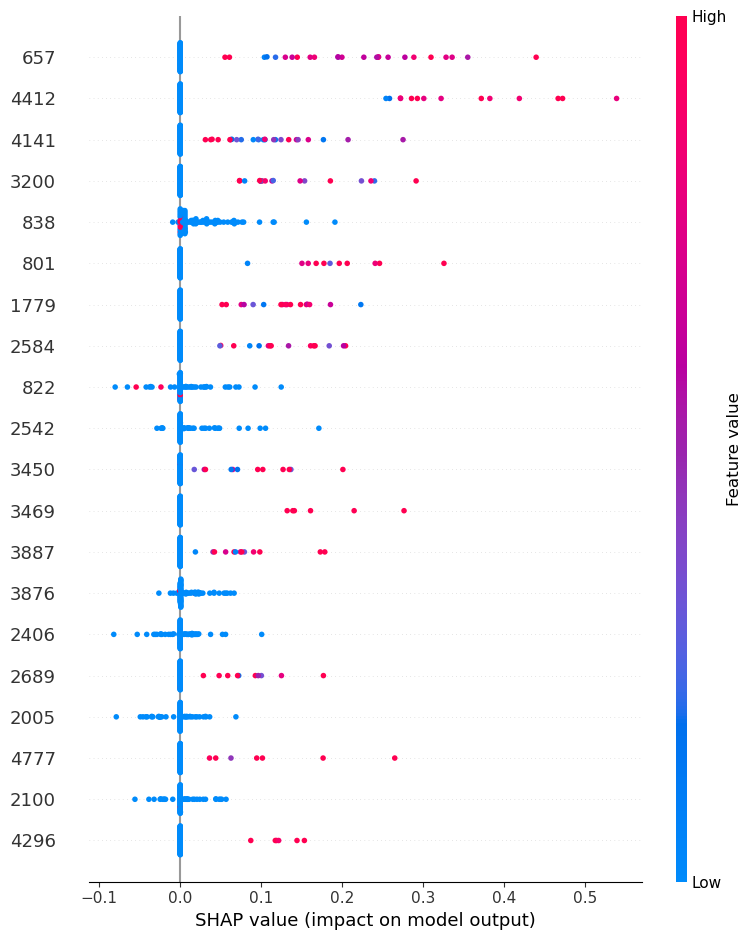

In [29]:
import shap

# Convert NumPy array to DataFrame
X_train_df = pd.DataFrame(X_train_np)  # Optionally add columns=feature_names if available

X_background = X_train_df.sample(2, random_state=42)
X_explain = X_train_df.sample(100, random_state=1)

explainer = shap.KernelExplainer(model.predict_proba, X_background)
shap_values = explainer.shap_values(X_explain, nsamples=100)

shap_class_1 = shap_values[:, :, 1]

print("SHAP shape:", shap_class_1.shape)
shap.summary_plot(shap_class_1, X_explain)